# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [7]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [8]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [9]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [10]:
df = pd.read_csv(PLIK_LODZ, sep=";")

df.head()
print(df.shape)
print(df.dtypes)

(65, 4)
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separotorem jest ten średnik ';', kolumna ma wartość liczbową int64, a polskie znaki wczytały się poprawnie

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [11]:
df["zmienna"].value_counts()

szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [12]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
roznica = (szeroka["kobiety"] + szeroka["mężczyźni"]) - szeroka["ogółem"]
roznica

,0
rok,
2012,0
2013,0
2014,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [13]:
# TODO: statystyki opisowe
szeroka.describe()

# TODO: zmiana procentowa 2012 → 2024
prc = ((szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012]) * 100
prc

# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka[["udzial_kobiet", "studenci_na_uczelnie"]]


zmienna,udzial_kobiet,studenci_na_uczelnie
rok,,
2012,0.60,4161.18
2013,0.60,3794.14
2014,0.60,3507.65
2015,0.60,3635.86
2016,0.60,3698.05
2017,0.60,3273.59
2018,0.60,3278.25
2019,0.59,3391.74
2020,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

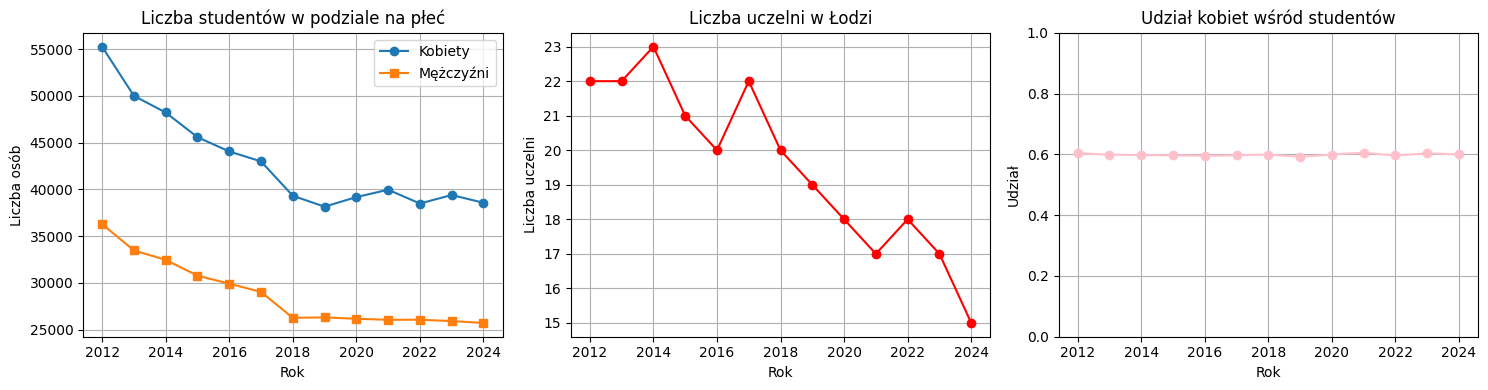

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka["kobiety"], marker="o", label="Kobiety")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], marker="s", label="Mężczyźni")
axes[0].set_title("Liczba studentów w podziale na płeć")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend()
axes[0].grid(True)

# TODO: wykres 2 — uczelnie
axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", color="red")
axes[1].set_title("Liczba uczelni w Łodzi")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")
axes[1].grid(True)

# TODO: wykres 3 — udział kobiet
axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="pink")
axes[2].set_title("Udział kobiet wśród studentów")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział")
axes[2].set_ylim(0, 1)
axes[2].grid(True)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Liczba studentów w tych latach spadła, tak samo jak liczba uczelni w Łodzi. Udział kobiet utrzymuje się na podobnym poziomie

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Przeciętne miesięczne wynagrodzenia brutto ogółem.csv · **link:** https://otwarte.miasto.lodz.pl/rynek-pracy/ · **data pobrania:** 22.10.2026

In [15]:
# TODO: wczytanie i przegląd Twojego zbioru
PLIK_PENSJA = "przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv"
upewnij_sie_ze_jest(PLIK_PENSJA)

Wgraj plik przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv:


Saving przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv to przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv


﻿id;rok;wartość;zmienne
64428;2002;2102,42;Przeciętne miesięczne wynagrodzenia brutto ogólem
64428;2003;2164,79;Przeciętne miesięczne wynagrodzenia brutto ogólem
(23, 4)
id           int64
rok          int64
wartość    float64
zmienne     object
dtype: object
id         0
rok        0
wartość    0
zmienne    0
dtype: int64


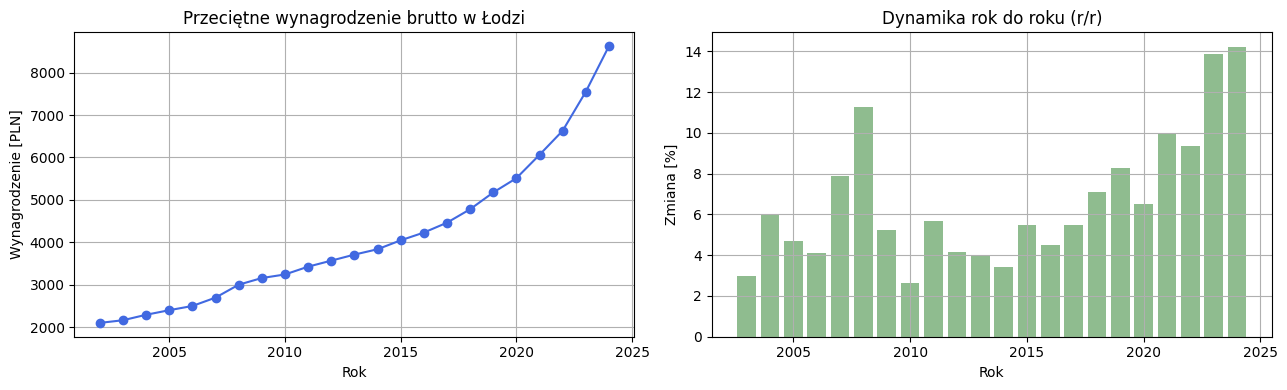

In [16]:
with open(PLIK_PENSJA, encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline().rstrip())

df_pensja = pd.read_csv(PLIK_PENSJA, sep=";", decimal=",")
df_pensja.head()
print(df_pensja.shape)
print(df_pensja.dtypes)

print(df_pensja.isna().sum())

szeroka_pensja = df_pensja.pivot(index="rok", columns="zmienne", values="wartość")
szeroka_pensja.describe()

nazwa_serii = szeroka_pensja.columns[0]
szeroka_pensja["zmiana_rdr_pct"] = szeroka_pensja[nazwa_serii].pct_change() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(szeroka_pensja.index, szeroka_pensja[nazwa_serii], marker="o", color="royalblue")
axes[0].set_title("Przeciętne wynagrodzenie brutto w Łodzi")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Wynagrodzenie [PLN]")
axes[0].grid(True)

axes[1].bar(szeroka_pensja.index[1:], szeroka_pensja["zmiana_rdr_pct"].dropna(), color="darkseagreen")
axes[1].set_title("Dynamika rok do roku (r/r)")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Zmiana [%]")
axes[1].grid(True)

plt.tight_layout()
plt.show()

✍️ **Wnioski:** Dane są bez braków i dziur, widać wzrost przeciętnego wynagordzenia brutto w Łodzi, które rośnie nieprzerwanie. Od 2020 roku widać dynamiczny wzrost przeciętnego wynagrodzenia, widać to również po słupkach procentowych rok do roku nabiera to tempa. Wyróżnia się również nagły wzrost w 2008 roku (prawie 12 pocent), a później mocne wyhamowanie do 2010 roku. Rok 2023 i 2024 są rekordowe pod względem dynamiki wzorstu procentowego rok do roku.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [17]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

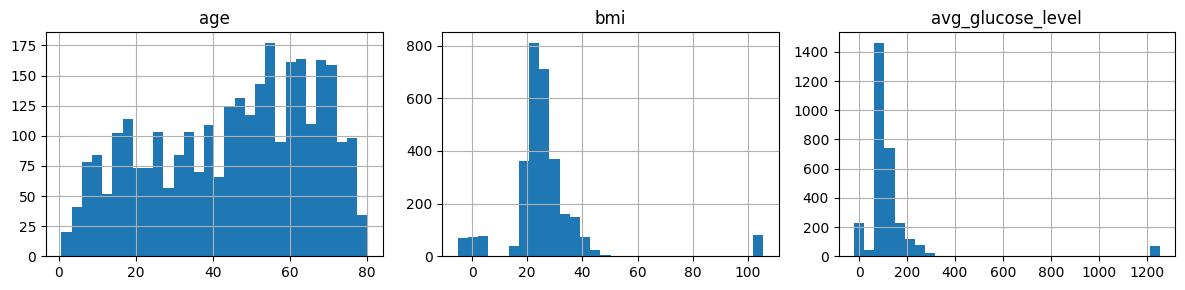

In [18]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
pacjenci[LICZBOWE].describe()

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(figsize=(12, 3), bins=30, layout=(1, 3))
plt.tight_layout()
plt.show()


✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Bmi powyżej 60 zaczyna być niemożliwe, a glukoza powyżej 800. Wartości ujemne też nie u ludzi nie zdarzają.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [19]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)
suma_zly = zle_bmi | zla_glukoza | zly_wiek
# TODO: liczebności
print(f"Liczba niemożliwych wartości BMI: {zle_bmi.sum()}")
print(f"Liczba niemożliwych wartości glukozy: {zla_glukoza.sum()}")
print(f"Liczba niemożliwych wartości wieku: {zly_wiek.sum()}")
print(f"Łączna liczba pacjentów z co najmniej jedną niemożliwą wartością: {suma_zly.sum()}")


# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan


Liczba niemożliwych wartości BMI: 300
Liczba niemożliwych wartości glukozy: 300
Liczba niemożliwych wartości wieku: 0
Łączna liczba pacjentów z co najmniej jedną niemożliwą wartością: 560


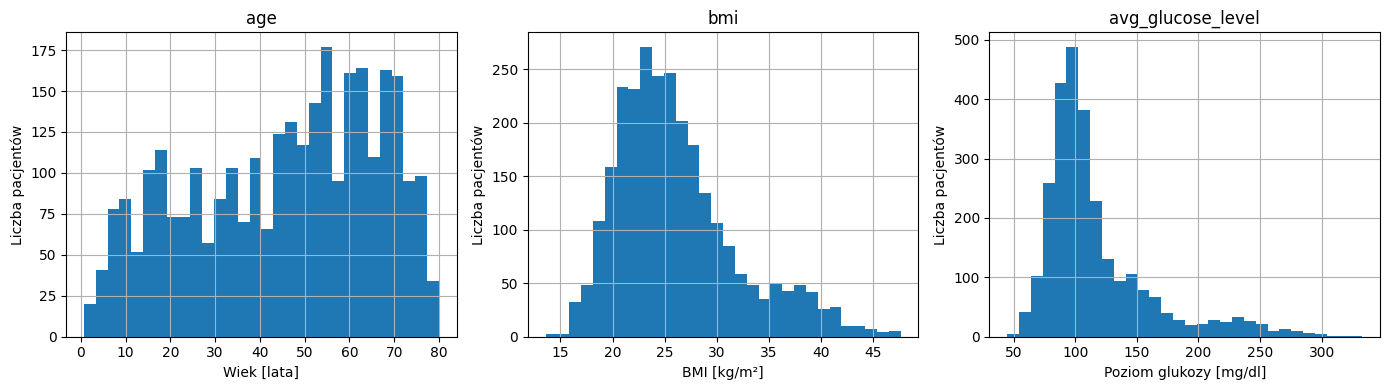

In [20]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
pacjenci[LICZBOWE].describe()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

pacjenci["age"].hist(ax=axes[0], bins=30)
axes[0].set_title("age")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Liczba pacjentów")
axes[0].grid(True)

pacjenci["bmi"].hist(ax=axes[1], bins=30)
axes[1].set_title("bmi")
axes[1].set_xlabel("BMI [kg/m²]")
axes[1].set_ylabel("Liczba pacjentów")
axes[1].grid(True)

pacjenci["avg_glucose_level"].hist(ax=axes[2], bins=30)
axes[2].set_title("avg_glucose_level")
axes[2].set_xlabel("Poziom glukozy [mg/dl]")
axes[2].set_ylabel("Liczba pacjentów")
axes[2].grid(True)

plt.tight_layout()
plt.show()


## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

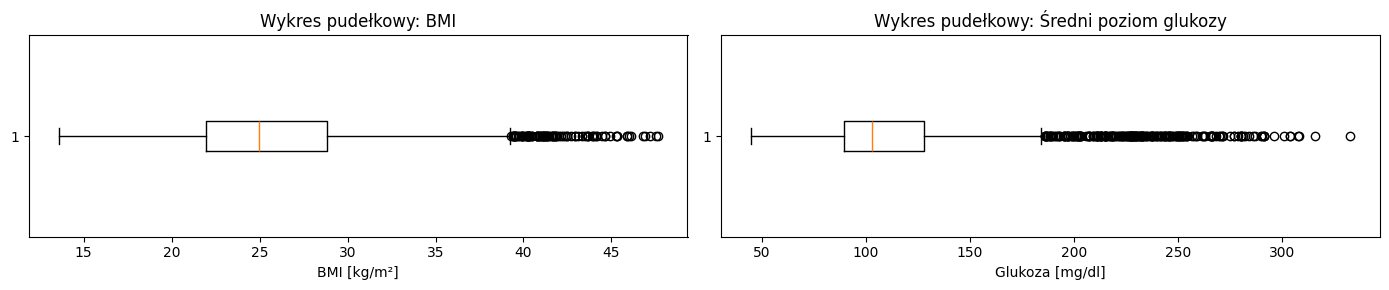

<Figure size 640x480 with 0 Axes>

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))


axes[0].boxplot(pacjenci["bmi"].dropna(), vert=False)
axes[0].set_title("Wykres pudełkowy: BMI")
axes[0].set_xlabel("BMI [kg/m²]")

axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), vert=False)
axes[1].set_title("Wykres pudełkowy: Średni poziom glukozy")
axes[1].set_xlabel("Glukoza [mg/dl]")
plt.tight_layout()
plt.show()


plt.tight_layout()
plt.show()

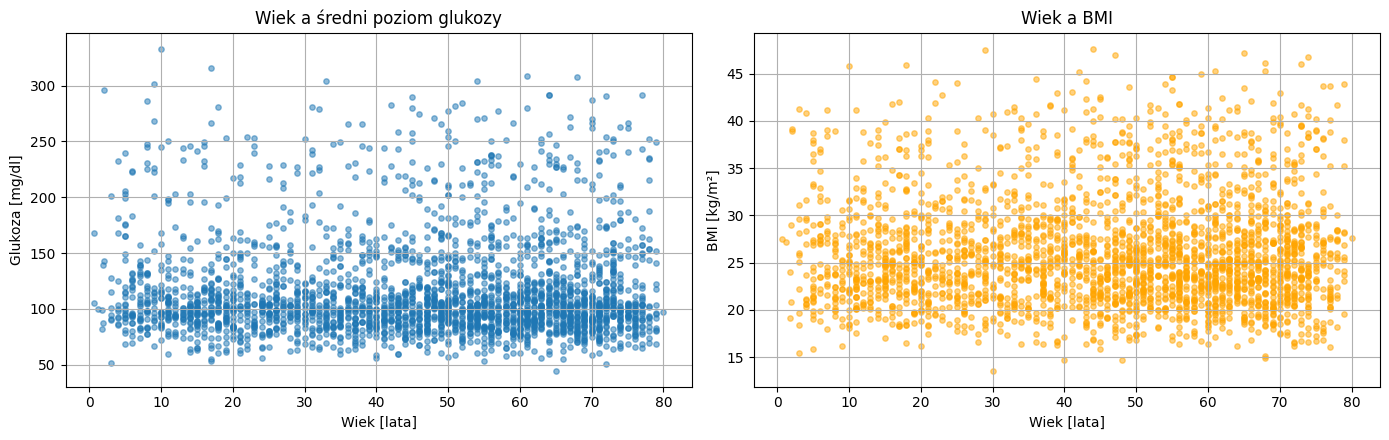

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], alpha=0.5, s=15)
axes[0].set_title("Wiek a średni poziom glukozy")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Glukoza [mg/dl]")
axes[0].grid(True)

axes[1].scatter(pacjenci["age"], pacjenci["bmi"], alpha=0.5, s=15, color="orange")
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("Wiek [lata]")
axes[1].set_ylabel("BMI [kg/m²]")
axes[1].grid(True)

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*

1. Dla zmiennej avg_glucose_level, całość punktów leży po prawej stronie pudełka
2. Wysokie wartości glukozy nie występują tylko w jednej grupie wiekowej, są w każdej. 10 latek z glukozą ponad 300mg/dl to nie jest błąd, tylko rzadki przypadek. Wartości ujemne czy powyżej 1000 zostały już usunięte.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [34]:
def maska_iqr(s, k=1.5):
    valid = s.dropna()
    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)
    iqr = q3 - q1
    return s.notna() & ((s < q1 - k * iqr) | (s > q3 + k * iqr))

def maska_z(s, prog=3):
    valid = s.dropna()
    mean = valid.mean()
    std = valid.std()
    z = (s - mean) / std
    return s.notna() & (z.abs() > prog)

def maska_mad(s, prog=3.5):
    valid = s.dropna()
    med = valid.median()
    mad = (valid - med).abs().median()
    z_m = 0.6745 * (s - med).abs() / mad
    return s.notna() & (z_m > prog)

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [35]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame({
    "IQR 1.5": [maska_iqr(pacjenci[c], 1.5).sum() for c in LICZBOWE],
    "IQR 3.0": [maska_iqr(pacjenci[c], 3.0).sum() for c in LICZBOWE],
    "z-score": [maska_z(pacjenci[c], 3).sum() for c in LICZBOWE],
    "MAD": [maska_mad(pacjenci[c], 3.5).sum() for c in LICZBOWE],
    "skew": [pacjenci[c].skew() for c in LICZBOWE]
}, index=LICZBOWE)

porownanie

,IQR 1.5,IQR 3.0,z-score,MAD,skew
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* …

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

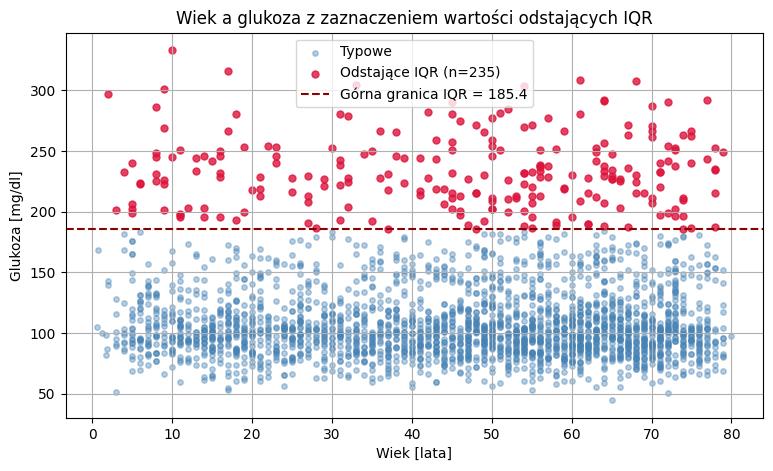

In [37]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
maska_gluk_iqr = maska_iqr(pacjenci["avg_glucose_level"], k=1.5)
q1 = pacjenci["avg_glucose_level"].quantile(0.25)
q3 = pacjenci["avg_glucose_level"].quantile(0.75)
prog_gorny = q3 + 1.5 * (q3 - q1)

plt.figure(figsize=(9, 5))
plt.scatter(pacjenci.loc[~maska_gluk_iqr, "age"], pacjenci.loc[~maska_gluk_iqr, "avg_glucose_level"],
            alpha=0.4, s=15, label="Typowe", color="steelblue")
plt.scatter(pacjenci.loc[maska_gluk_iqr, "age"], pacjenci.loc[maska_gluk_iqr, "avg_glucose_level"],
            alpha=0.8, s=25, label=f"Odstające IQR (n={maska_gluk_iqr.sum()})", color="crimson")
plt.axhline(prog_gorny, color="darkred", linestyle="--", label=f"Górna granica IQR = {prog_gorny:.1f}")
plt.title("Wiek a glukoza z zaznaczeniem wartości odstających IQR")
plt.xlabel("Wiek [lata]")
plt.ylabel("Glukoza [mg/dl]")
plt.legend()
plt.grid(True)
plt.show()


### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

avg_glucose_level
False   21.92
True    21.70
Name: stroke, dtype: float64


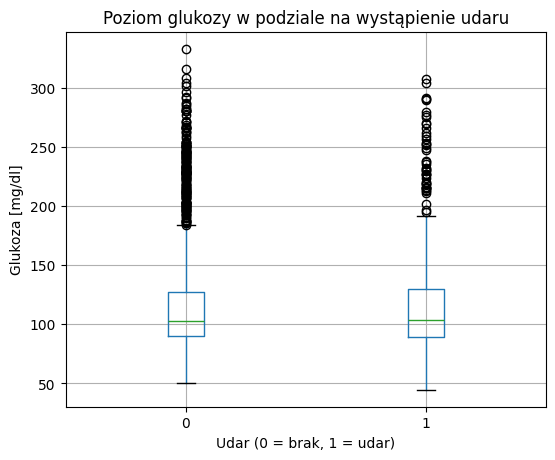

In [38]:
odsetek_udarow = pacjenci.groupby(maska_gluk_iqr)["stroke"].mean() * 100
print(odsetek_udarow)

pacjenci.boxplot(column="avg_glucose_level", by="stroke", figsize=(6, 5))
plt.title("Poziom glukozy w podziale na wystąpienie udaru")
plt.suptitle("")
plt.xlabel("Udar (0 = brak, 1 = udar)")
plt.ylabel("Glukoza [mg/dl]")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie powinno usuwać się pacjentów z wysoką glukozą jeżeli chcielibyśmy przewidzieć udar, jest to jedna z kluczowych cech do przewidzenia.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [39]:
pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"])

dziecko_pali = (
    (pacjenci["work_type"] == "children") &
    pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
)

maluch_student = (
    (pacjenci["age"] <= 3) &
    (pacjenci["work_type"] == "student")
)

print(dziecko_pali.sum(), maluch_student.sum())
pacjenci[dziecko_pali | maluch_student]

15 1


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,NaN,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,NaN,15.47,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,NaN,20.93,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Metody te są jednowymiarowe, więc operują na pojedyńczych zmiennych liczbowych więc nie dałoby się.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [41]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=X.shape[1])

print(prog)
print((d2 > prog).sum())
print((Z.loc[d2 > prog] ** 2).idxmax(axis=1).value_counts())


11.344866730144373
73
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

31


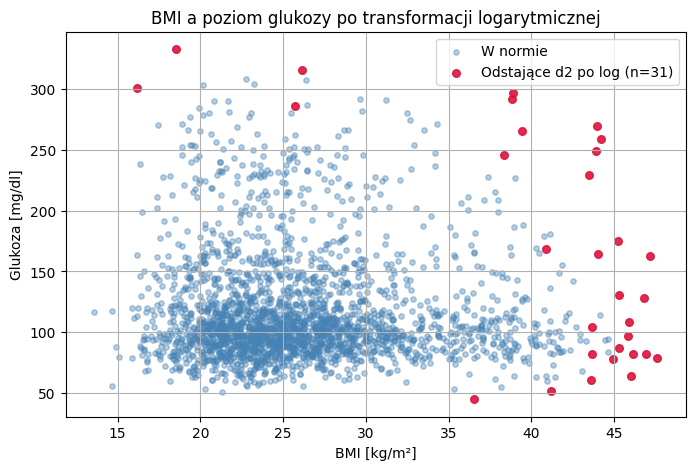

Korelacja:


,age,bmi,avg_glucose_level
age,1.00,0.02,0.01
bmi,0.02,1.00,-0.02
avg_glucose_level,0.01,-0.02,1.00


In [45]:
X_log = X.assign(avg_glucose_level=np.log(X["avg_glucose_level"]))
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)

print((d2_log > prog).sum())

odstajace_log = d2_log > prog

plt.figure(figsize=(8, 5))
plt.scatter(X.loc[~odstajace_log, "bmi"], X.loc[~odstajace_log, "avg_glucose_level"],
            alpha=0.4, s=15, label="W normie", color="steelblue")
plt.scatter(X.loc[odstajace_log, "bmi"], X.loc[odstajace_log, "avg_glucose_level"],
            alpha=0.9, s=30, label=f"Odstające d2 po log (n={odstajace_log.sum()})", color="crimson")
plt.title("BMI a poziom glukozy po transformacji logarytmicznej")
plt.xlabel("BMI [kg/m²]")
plt.ylabel("Glukoza [mg/dl]")
plt.legend()
plt.grid(True)
plt.show()

print("Korelacja:")
X.corr()


✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Odległość Mahalanobisa uwzględnia macierz kowariancji i orientację chmury punktów, więc nie dałaby rady.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [46]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
maska_iso = iso.fit_predict(X_log) == -1

wspolne = (maska_iso & (d2_log > prog)).sum()
print(maska_iso.sum())
print(wspolne)

25
19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [47]:
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = zle_bmi | zla_glukoza | zly_wiek
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"], k=1.5).reindex(oryginal.index, fill_value=False)
flagi["nielogiczna_kategoria"] = (dziecko_pali | maluch_student).reindex(oryginal.index, fill_value=False)
flagi["odlegly_od_srodka"] = (d2_log > prog).reindex(oryginal.index, fill_value=False)

print(flagi.sum())
print((flagi.any(axis=1)).sum())

niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN | Są to błędy pomiarowe/szum. |
| wysoka glukoza (IQR) | zostawić / log | Rzeczywiste zmiany chorobowe, najlpiej skońność niwelować transformacja logartytmiczną |
| nielogiczne kategorie | poprawić / usunąć | Trzeba je poprawić i usunąc, aby nie wprowadzały niepotrzebnego szumu dla danych. |
| odlegli od środka | flaga | Nietypowe multizmienne kombinacje mogą reprezentować specyficzne podgrupy pacjentów i warto kontrolować ich wpływ na wagi modeli odpornych. |